In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime
import os
from scipy.signal import find_peaks

/usr/lib/python3/dist-packages/scipy/__init__.py:146: UserWarning: A NumPy version >=1.17.3 and <1.25.0 is required for this version of SciPy (detected version 1.26.4
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion}"


In [2]:
path="/mnt/c/Users/isabe/OneDrive/Desktop/Lavoro/Tuscia/chiara/peaks_background/bufale_isa/"
os.chdir(path)

In [3]:
mandria_path = './dati_bufale/dati_grezzi_agosto_luglio/Agosto/protocollo_2/ch4_cutted_milkings.csv'
mandria = pd.read_csv(mandria_path)
matrix=[]
peaks=[]

In [5]:
mandria.head()

,timestamp,CH4,date,Ora inizio,Produzione (kg),ID_animal,Milking_duration,Milking_number,milking_duration_seconds,progressive_seconds
0,2024-08-01 10:23:58.514944,4.9,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,1
1,2024-08-01 10:23:59.516324,8.9,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,2
2,2024-08-01 10:24:00.519414,11.5,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,3
3,2024-08-01 10:24:01.521864,13.4,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,4
4,2024-08-01 10:24:02.524778,13.2,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,5


In [4]:
mungiture = list(set(mandria['Milking_number']))
#print(len(animals))
print(len(mungiture))

1810


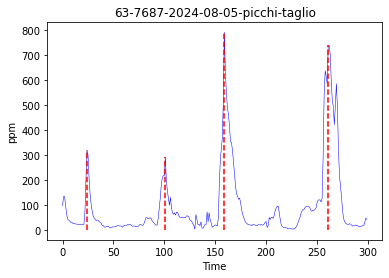

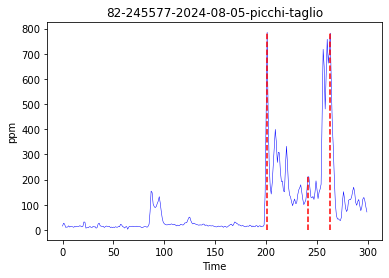

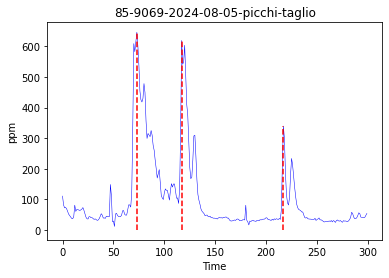

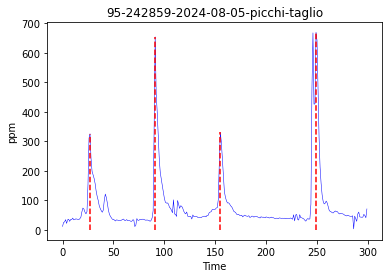

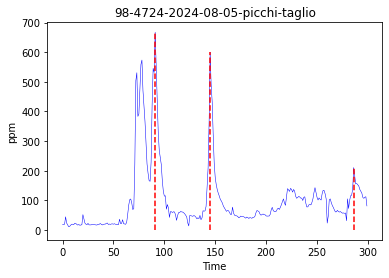

...

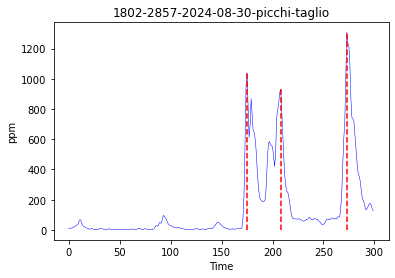

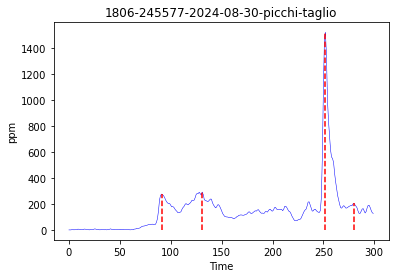

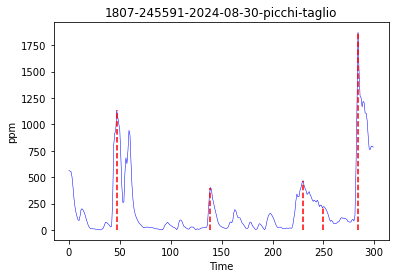

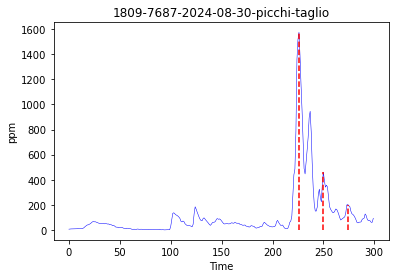

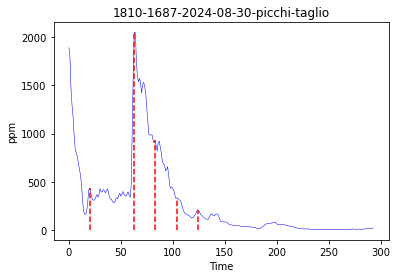

401


In [60]:
mungiture_peaks = list()
for mungitura in mungiture:  

    milking_ch4 = mandria[mandria['Milking_number'] == mungitura]
    milking_ch4 = milking_ch4.reset_index(drop=True)
    
    ch4=milking_ch4['CH4']
        
    animal = milking_ch4.iloc[0,5]
    date = milking_ch4.iloc[0,2]

    
    #Wait 20 sec before the detection of the next peak
    time_interval=20
    
    # Find peaks
    peaks, properties = find_peaks(ch4, height=200, distance=time_interval)
    
    # Count the number of peaks
    num_peaks = len(peaks)
    
    # Save the count to a new column in the DataFrame
    milking_ch4['num_peaks'] = num_peaks
    
    
    if num_peaks >= 3:
        #print(mungitura)
        mungiture_peaks.append(mungitura)
        
        matrix.append(milking_ch4)
    
        #Plot singole mungiture 
        plt.figure(facecolor='white')
        plt.xlabel('Time')
        plt.ylabel('ppm')
    
        title = str(mungitura) + "-" + str(animal) + "-" + str(date) + "-picchi-taglio" 
        plt.title(title)
        plt.plot(milking_ch4['CH4'], linewidth=0.5, color = "blue")
        plt.vlines(peaks, ymin=0, ymax=properties['peak_heights'], color='red', linestyles='--')
        
        #directory = os.path.join("./dati_bufale/dati_grezzi_agosto_luglio/Dataset_CH4/Bufale_Rinna/Luglio/protocollo_2/plot_bufale/", str(animal))
        #if not os.path.exists(directory):
        #    os.makedirs(directory)
        #file_path = os.path.join(directory, (str(mungitura) + "-original.png"))
        #plt.savefig(file_path, format="png", dpi=250)
        
        plt.show()

print(len(mungiture_peaks))

#Concatenate all DataFrames in the list into a single DataFrame
combined_df = pd.concat(matrix, ignore_index=True)

#combined_df.drop(columns=['CH4_det','Entry_time',
                      #'Milking_duration','Exit_time','ID_cow',
                      #'milking_duration_seconds','progressive_seconds'], inplace=True)

# Salva il DataFrame combinato in un nuovo file CSV.
output_file = './dati_bufale/dati_grezzi_agosto_luglio/Agosto/protocollo_2/ch4_milking_tot_peaks_200_3.csv'
combined_df.to_csv(output_file, index=False)



In [61]:
peaks

array([], dtype=int64)

In [32]:
combined_df.head(50)

,timestamp,CH4,date,Ora inizio,Produzione (kg),ID_animal,Milking_duration,Milking_number,milking_duration_seconds,progressive_seconds,num_peaks
0,2024-08-01 10:23:58.514944,4.9,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,1,0
1,2024-08-01 10:23:59.516324,8.9,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,2,0
2,2024-08-01 10:24:00.519414,11.5,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,3,0
3,2024-08-01 10:24:01.521864,13.4,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,4,0
4,2024-08-01 10:24:02.524778,13.2,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,5,0
5,2024-08-01 10:24:03.527285,8.7,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,6,0
6,2024-08-01 10:24:04.529165,7.7,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,7,0
7,2024-08-01 10:24:05.532324,10.5,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,8,0
8,2024-08-01 10:24:06.534901,10.3,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,9,0
9,2024-08-01 10:24:07.538166,9.9,2024-08-01,2024-08-01 10:23:00,5.55,7854,9.18,5,558,10,0
